In [ ]:
import numpy as np, pandas as pd

hidden = np.load("hidden_features.npy")          # [1916, 131072]
sids   = np.load("signal_sample_ids.npy", allow_pickle=True)
meta   = pd.read_parquet("strat_v2_behavior.parquet").set_index("sample_id").loc[sids].reset_index()

# 층 슬라이스 (concat: layer L → [L*4096:(L+1)*4096])
def layer(L):
    return hidden[:, L*4096:(L+1)*4096]   # [1916, 4096]

h17, h18 = layer(17), layer(18)

# 확인
print("hidden:", hidden.shape, "| 층 슬라이스:", h17.shape)
print("정렬 확인 (meta와 행 일치):", len(meta)==len(hidden))
print("K 분포:", meta["K"].value_counts().to_dict())
print("dataset 분포:", meta["dataset_id"].value_counts().to_dict())
print("behavior 분포:", meta["behavior"].value_counts().to_dict())
print("라벨 컬럼:", [c for c in meta.columns if c in
      ["K","behavior","dataset_id","fact_nature","construction_operator","instability","prompt_len","prompt_len_trunc"]])

hidden: (1916, 131072) | 층 슬라이스: (1916, 4096)
정렬 확인 (meta와 행 일치): True
K 분포: {'K-': 968, 'K+': 948}
dataset 분포: {'clasheval': 480, 'confiqa_qa': 480, 'dynamicqa': 479, 'nqswap': 477}
behavior 분포: {'accepted_context': 846, 'both': 352, 'retained_parametric': 323, 'other': 264, 'abstain': 131}
라벨 컬럼: ['dataset_id', 'fact_nature', 'construction_operator', 'K', 'prompt_len', 'instability', 'behavior']


In [ ]:
import numpy as np, matplotlib.pyplot as plt

y = (meta["K"]=="K+").values.astype(int)  # K+ =1, K- =0

def cohens_d(x, y):
    """차원별 두 집단 분리도. |d| 클수록 잘 갈림"""
    x1, x0 = x[y==1], x[y==0]
    n1, n0 = len(x1), len(x0)
    pooled_sd = np.sqrt(((n1-1)*x1.var(ddof=1) + (n0-1)*x0.var(ddof=1)) / (n1+n0-2))
    return (x1.mean() - x0.mean()) / (pooled_sd + 1e-9)

def rank_dims(H, y, name):
    d = np.array([cohens_d(H[:,j], y) for j in range(H.shape[1])])
    order = np.argsort(-np.abs(d))
    print(f"\n=== {name}: |Cohen's d| 상위 10 차원 ===")
    for r in order[:10]:
        print(f"  dim {r}: d={d[r]:+.3f}")
    print(f"  |d|>0.5 차원 수: {(np.abs(d)>0.5).sum()} / {H.shape[1]}")
    print(f"  |d|>0.8 차원 수: {(np.abs(d)>0.8).sum()}")
    return d, order

d17, ord17 = rank_dims(h17, y, "layer 17")
d18, ord18 = rank_dims(h18, y, "layer 18")

# 상위 차원 단독 threshold 정확도 (트레이닝-프리 스토리 기준선)
from sklearn.metrics import roc_auc_score
def single_dim_acc(x, y):
    # 최적 threshold = 두 집단 평균의 중점
    thr = (x[y==1].mean() + x[y==0].mean()) / 2
    pred = (x > thr).astype(int) if x[y==1].mean() > x[y==0].mean() else (x < thr).astype(int)
    return (pred==y).mean(), roc_auc_score(y, x if x[y==1].mean()>x[y==0].mean() else -x)

print("\n=== 상위 3개 차원 단독 threshold 성능 ===")
for L, H, order in [("L17",h17,ord17),("L18",h18,ord18)]:
    for r in order[:3]:
        acc, auc = single_dim_acc(H[:,r], y)
        print(f"  {L} dim{r}: acc={acc:.3f}, AUROC={auc:.3f}")


=== layer 17: |Cohen's d| 상위 10 차원 ===
  dim 34: d=-0.224
  dim 3728: d=-0.201
  dim 1145: d=-0.198
  dim 681: d=+0.189
  dim 281: d=+0.189
  dim 3847: d=-0.189
  dim 2738: d=+0.187
  dim 2681: d=+0.186
  dim 1890: d=-0.183
  dim 3546: d=+0.182
  |d|>0.5 차원 수: 0 / 4096
  |d|>0.8 차원 수: 0

=== layer 18: |Cohen's d| 상위 10 차원 ===
  dim 34: d=-0.236
  dim 3044: d=+0.217
  dim 1808: d=-0.200
  dim 595: d=-0.195
  dim 3546: d=+0.195
  dim 1145: d=-0.194
  dim 1855: d=-0.193
  dim 203: d=-0.184
  dim 634: d=-0.181
  dim 3778: d=-0.179
  |d|>0.5 차원 수: 0 / 4096
  |d|>0.8 차원 수: 0

=== 상위 3개 차원 단독 threshold 성능 ===
  L17 dim34: acc=0.552, AUROC=0.568
  L17 dim3728: acc=0.554, AUROC=0.560
  L17 dim1145: acc=0.545, AUROC=0.560
  L18 dim34: acc=0.537, AUROC=0.568
  L18 dim3044: acc=0.554, AUROC=0.564
  L18 dim1808: acc=0.530, AUROC=0.559


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# behavior 이진 (accept vs retain, K- 내부 — 우리 핵심 타겟)
m = (meta["K"]=="K-") & meta["behavior"].isin(["accepted_context","retained_parametric"])
m = m.values
yb = (meta[m]["behavior"]=="accepted_context").astype(int).values

# 1) behavior 단일 차원 분리도
print("=== behavior(accept/retain) 단일 차원 Cohen's d ===")
for L, H in [("L17",h17),("L18",h18)]:
    db = np.array([cohens_d(H[m][:,j], yb) for j in range(H.shape[1])])
    print(f"  {L}: 최대 |d|={np.abs(db).max():.3f}, |d|>0.5 차원={np.abs(db>0.5).sum()}")

# 2) probe 방향으로 투영 → 이게 분포 시각화의 핵심
#    다차원 조합(probe)이 만든 1D 축에서 K+/K- 또는 accept/retain이 갈리나
def probe_projection(H, y, label):
    Hs = StandardScaler().fit_transform(H)
    clf = LogisticRegression(max_iter=1000, C=0.1).fit(Hs, y)
    proj = Hs @ clf.coef_[0]   # probe 방향 투영 (1D)
    d = cohens_d(proj, y)
    return proj, d

# K± probe 투영
proj_k17, dk17 = probe_projection(h17, y, "K")
proj_k18, dk18 = probe_projection(h18, y, "K")
# behavior probe 투영
proj_b17, db17 = probe_projection(h17[m], yb, "beh")
proj_b18, db18 = probe_projection(h18[m], yb, "beh")

print("\n=== probe 방향 투영 후 Cohen's d (다차원 조합) ===")
print(f"  K± L17: d={dk17:.3f} | L18: d={dk18:.3f}")
print(f"  behavior L17: d={db17:.3f} | L18: d={db18:.3f}")
print("  (단일 차원 최고 0.24와 비교 — 조합하면 얼마나 커지나)")

=== behavior(accept/retain) 단일 차원 Cohen's d ===
  L17: 최대 |d|=0.542, |d|>0.5 차원=1
  L18: 최대 |d|=0.596, |d|>0.5 차원=0

=== probe 방향 투영 후 Cohen's d (다차원 조합) ===
  K± L17: d=3.498 | L18: d=3.446
  behavior L17: d=4.816 | L18: d=4.695
  (단일 차원 최고 0.24와 비교 — 조합하면 얼마나 커지나)


OOF 투영 Cohen's d — K±: 0.07 | behavior: -0.04 (과적합 제거 후)


/tmp/ipykernel_1410/2584315568.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([h18[y==0, best_k], h18[y==1, best_k]], labels=["K-","K+"])
/tmp/ipykernel_1410/2584315568.py:42: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([h18[m][yb==0, best_b], h18[m][yb==1, best_b]], labels=["retain","accept"])
/tmp/ipykernel_1410/2584315568.py:53: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1410/2584315568.py:53: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1410/2584315568.py:53: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  plt.tight_la

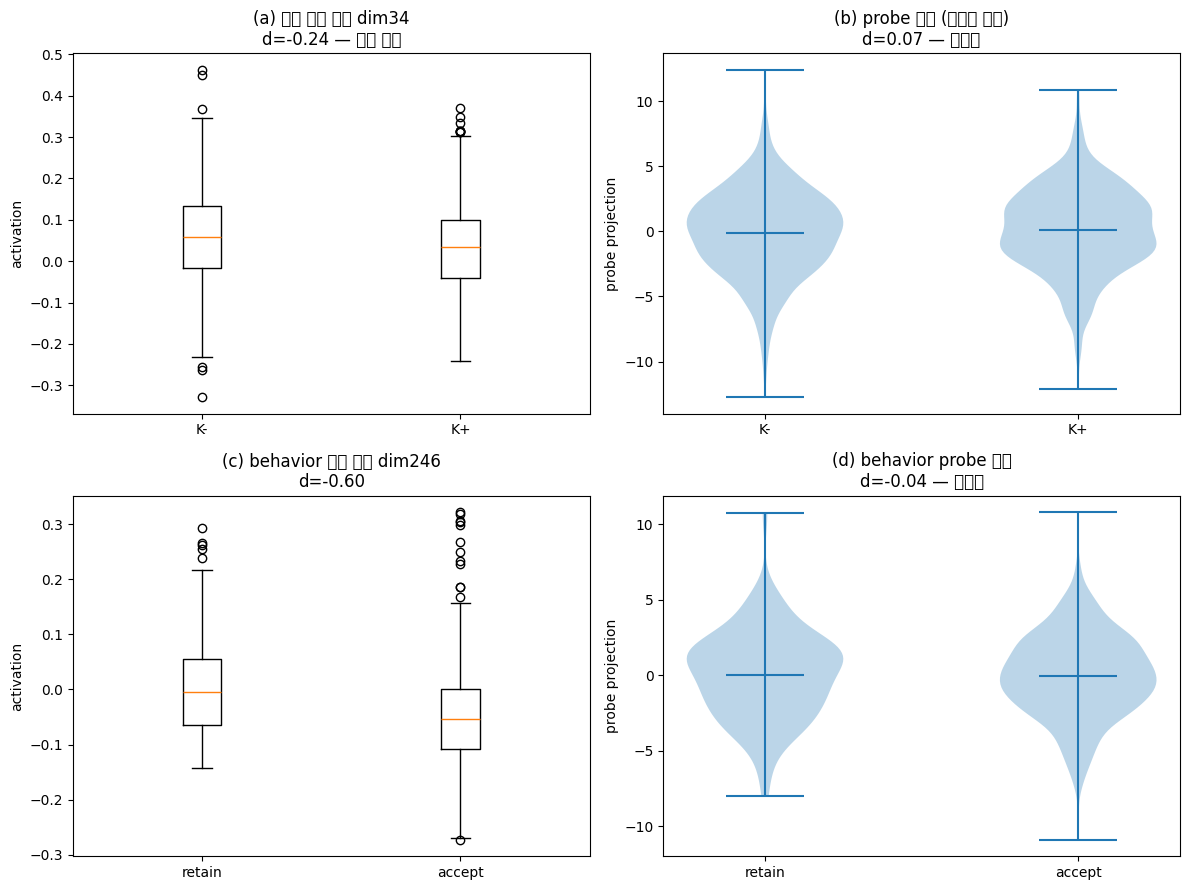

저장: layer18_distribution.png


In [ ]:
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

def oof_projection(H, y, groups):
    """out-of-fold 투영 — 과적합 없는 정직한 축"""
    Hs = StandardScaler().fit_transform(H)
    proj = np.zeros(len(y))
    for tr, te in GroupKFold(5).split(Hs, y, groups):
        clf = LogisticRegression(max_iter=1000, C=0.1).fit(Hs[tr], y[tr])
        proj[te] = Hs[te] @ clf.coef_[0]
    return proj

g_all = meta["question"].values
g_beh = meta[m]["question"].values

# OOF 투영 (L18 기준)
projK = oof_projection(h18, y, g_all)
projB = oof_projection(h18[m], yb, g_beh)
dK = cohens_d(projK, y); dB = cohens_d(projB, yb)
print(f"OOF 투영 Cohen's d — K±: {dK:.2f} | behavior: {dB:.2f} (과적합 제거 후)")

# === 시각화: 2×2 ===
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# (a) K± 단일 최고 차원 (안 갈림)
ax = axes[0,0]
best_k = np.argmax([abs(cohens_d(h18[:,j], y)) for j in range(4096)])
ax.boxplot([h18[y==0, best_k], h18[y==1, best_k]], labels=["K-","K+"])
ax.set_title(f"(a) 단일 최고 차원 dim{best_k}\nd={cohens_d(h18[:,best_k],y):.2f} — 거의 겹침")
ax.set_ylabel("activation")

# (b) K± probe 방향 (갈림)
ax = axes[0,1]
parts = ax.violinplot([projK[y==0], projK[y==1]], showmeans=True)
ax.set_xticks([1,2]); ax.set_xticklabels(["K-","K+"])
ax.set_title(f"(b) probe 방향 (다차원 조합)\nd={dK:.2f} — 분리됨")
ax.set_ylabel("probe projection")

# (c) behavior 단일 최고
ax = axes[1,0]
best_b = np.argmax([abs(cohens_d(h18[m][:,j], yb)) for j in range(4096)])
ax.boxplot([h18[m][yb==0, best_b], h18[m][yb==1, best_b]], labels=["retain","accept"])
ax.set_title(f"(c) behavior 단일 최고 dim{best_b}\nd={cohens_d(h18[m][:,best_b],yb):.2f}")
ax.set_ylabel("activation")

# (d) behavior probe 방향
ax = axes[1,1]
ax.violinplot([projB[yb==0], projB[yb==1]], showmeans=True)
ax.set_xticks([1,2]); ax.set_xticklabels(["retain","accept"])
ax.set_title(f"(d) behavior probe 방향\nd={dB:.2f} — 분리됨")
ax.set_ylabel("probe projection")

plt.tight_layout()
plt.savefig("layer18_distribution.png", dpi=120, bbox_inches="tight")
plt.show()
print("저장: layer18_distribution.png")

In [ ]:
from sklearn.metrics import roc_auc_score

# 같은 OOF 투영으로 d와 AUROC 둘 다 계산 (정합성)
def oof_check(H, y, groups, name):
    Hs = StandardScaler().fit_transform(H)
    proj = np.zeros(len(y))
    for tr, te in GroupKFold(5).split(Hs, y, groups):
        # fold 내부에서 scaler 다시 fit (leakage 방지)
        sc = StandardScaler().fit(H[tr])
        clf = LogisticRegression(max_iter=1000, C=0.1).fit(sc.transform(H[tr]), y[tr])
        proj[te] = sc.transform(H[te]) @ clf.coef_[0]
    d = cohens_d(proj, y)
    auc = roc_auc_score(y, proj)
    print(f"  {name}: OOF d={d:.3f}, AUROC={auc:.3f}")
    return proj

print("=== 층별 behavior probe OOF (정합성 체크) ===")
for L in [16, 17, 18, 20]:
    hL = layer(L)
    oof_check(hL[m], yb, meta[m]["question"].values, f"behavior L{L}")

print("\n=== 층별 K± probe OOF ===")
for L in [16, 17, 18, 20]:
    hL = layer(L)
    oof_check(hL, y, meta["question"].values, f"K± L{L}")

=== 층별 behavior probe OOF (정합성 체크) ===
  behavior L16: OOF d=0.000, AUROC=0.500
  behavior L17: OOF d=-0.124, AUROC=0.473
  behavior L18: OOF d=-0.039, AUROC=0.493
  behavior L20: OOF d=0.063, AUROC=0.522

=== 층별 K± probe OOF ===
  K± L16: OOF d=0.091, AUROC=0.523
  K± L17: OOF d=0.063, AUROC=0.514
  K± L18: OOF d=0.066, AUROC=0.519
  K± L20: OOF d=0.036, AUROC=0.506


In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Phase 3 방식 그대로 재현
hidden_3d = hidden.reshape(1916, 32, 4096)

# 두 방식이 같은 데이터인지 직접 비교
L = 20
via_slice = hidden[:, L*4096:(L+1)*4096]
via_reshape = hidden_3d[:, L, :]
print("슬라이스 == reshape?:", np.allclose(via_slice, via_reshape))
print("  슬라이스 [0,:5]:", via_slice[0,:5])
print("  reshape  [0,:5]:", via_reshape[0,:5])

# behavior 마스크 재현 (Phase 3와 동일하게)
mb = ((meta["K"]=="K-") & meta["behavior"].isin(["accepted_context","retained_parametric"])).values
yb2 = (meta[mb]["behavior"]=="accepted_context").astype(int).values
gb2 = meta[mb]["question"].values
print(f"\nbehavior 마스크: {mb.sum()}개, accept={yb2.sum()}, retain={(1-yb2).sum()}")

def probe_auc(H, y, groups):
    gkf = GroupKFold(5); aucs=[]
    for tr,te in gkf.split(H,y,groups):
        sc=StandardScaler().fit(H[tr])
        clf=LogisticRegression(max_iter=1000,C=0.1).fit(sc.transform(H[tr]),y[tr])
        if len(np.unique(y[te]))>1:
            aucs.append(roc_auc_score(y[te], clf.predict_proba(sc.transform(H[te]))[:,1]))
    return np.mean(aucs)

# 두 방식으로 각각 probe
print("\n=== Phase 3 재현 시도 ===")
print(f"  reshape [:,20,:]:  AUROC={probe_auc(hidden_3d[mb,20,:], yb2, gb2):.3f}")
print(f"  slice  20*4096:    AUROC={probe_auc(hidden[mb][:, 20*4096:21*4096], yb2, gb2):.3f}")

슬라이스 == reshape?: True
  슬라이스 [0,:5]: [0.22351074 0.12927246 0.31591797 0.04324341 0.06396484]
  reshape  [0,:5]: [0.22351074 0.12927246 0.31591797 0.04324341 0.06396484]

behavior 마스크: 607개, accept=524, retain=83

=== Phase 3 재현 시도 ===
  reshape [:,20,:]:  AUROC=0.521
  slice  20*4096:    AUROC=0.521


In [ ]:
# signal_sample_ids와 meta의 sample_id가 진짜 같은 순서인지
print("=== 정렬 검증 ===")
print("sids 앞 5개:", sids[:5])
print("meta sample_id 앞 5개:", meta["sample_id"].values[:5])
print("완전 일치?:", (sids == meta["sample_id"].values).all())

# meta를 sids 순서로 재정렬했었나? 로딩 코드 재확인
meta_check = pd.read_parquet("strat_v2_behavior.parquet")
print("\nparquet 원본 순서 == sids?:", (meta_check["sample_id"].values == sids).all())
print("parquet 원본 첫 5:", meta_check["sample_id"].values[:5])

# 만약 순서 다르면 — sids 기준으로 재정렬
if not (meta["sample_id"].values == sids).all():
    print("\n⚠️ 순서 불일치! sids 기준 재정렬 필요")
    meta_aligned = meta_check.set_index("sample_id").loc[sids].reset_index()
    # 재정렬 후 probe 재시도
    mb2 = ((meta_aligned["K"]=="K-") & meta_aligned["behavior"].isin(["accepted_context","retained_parametric"])).values
    yb3 = (meta_aligned[mb2]["behavior"]=="accepted_context").astype(int).values
    gb3 = meta_aligned[mb2]["question"].values
    print(f"재정렬 후 behavior L20 AUROC={probe_auc(hidden[mb2][:,20*4096:21*4096], yb3, gb3):.3f}")
else:
    print("\n순서는 맞음 → hidden 파일 자체가 다른 추출일 가능성")

=== 정렬 검증 ===
sids 앞 5개: ['clasheval_1902' 'clasheval_2491' 'clasheval_1258' 'clasheval_2000'
 'clasheval_2627']
meta sample_id 앞 5개: ['clasheval_1902' 'clasheval_2491' 'clasheval_1258' 'clasheval_2000'
 'clasheval_2627']
완전 일치?: True

parquet 원본 순서 == sids?: True
parquet 원본 첫 5: ['clasheval_1902' 'clasheval_2491' 'clasheval_1258' 'clasheval_2000'
 'clasheval_2627']

순서는 맞음 → hidden 파일 자체가 다른 추출일 가능성


In [ ]:
# preanswer_perhead는 Phase 3에서 0.793 냈던 파일. 이걸로 교차 확인.
pre_ph = np.load("preanswer_perhead.npy")   # [1916, 2048]
print("preanswer_perhead:", pre_ph.shape)

mb = ((meta["K"]=="K-") & meta["behavior"].isin(["accepted_context","retained_parametric"])).values
ybb = (meta[mb]["behavior"]=="accepted_context").astype(int).values
gbb = meta[mb]["question"].values

# pre-answer probe 재현 (Phase 3에서 0.793이었음)
print("pre-answer per-head AUROC:", round(probe_auc(pre_ph[mb], ybb, gbb), 3))

# hidden 전체 층 스윕 — 혹시 특정 층은 살아있나
print("\n=== hidden 전체 층 behavior AUROC 스윕 ===")
best = (0, 0)
for L in range(0, 32, 2):
    auc = probe_auc(hidden[mb][:, L*4096:(L+1)*4096], ybb, gbb)
    if auc > best[1]: best = (L, auc)
    print(f"  L{L}: {auc:.3f}")
print(f"\n최고: L{best[0]} = {best[1]:.3f}")

preanswer_perhead: (1916, 2048)
pre-answer per-head AUROC: 0.81

=== hidden 전체 층 behavior AUROC 스윕 ===
  L0: 0.550
  L2: 0.491
  L4: 0.519
  L6: 0.522
  L8: 0.510
  L10: 0.541
  L12: 0.540
  L14: 0.507
  L16: 0.494
  L18: 0.493
  L20: 0.521
  L22: 0.539
  L24: 0.536
  L26: 0.566
  L28: 0.559
  L30: 0.566

최고: L26 = 0.566


In [ ]:
import torch, time, gc
from transformers import AutoModelForCausalLM, AutoTokenizer
from tqdm.auto import tqdm
from huggingface_hub import login
login()

MODEL_ID = "meta-llama/Llama-3.1-8B-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, dtype=torch.float16, device_map="cuda", attn_implementation="eager")
model.eval()
if tok.pad_token is None: tok.pad_token = tok.eos_token
tok.padding_side = "left"
print("모델 로딩 완료")

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

모델 로딩 완료


In [ ]:
print("context_trunc 있나:", "context_trunc" in meta.columns)
print("question 있나:", "question" in meta.columns)
if "context_trunc" in meta.columns:
    print("예시:", meta["context_trunc"].iloc[0][:80])

context_trunc 있나: True
question 있나: True
예시:  Nike CEO on November 18, 2004, several months after Matthew's funeral, but reta


In [ ]:
import numpy as np, time, gc

def build_neutral_prompt(question, context):
    msgs = [{"role":"user","content":f"Context: {context}\n\nQuestion: {question}\nAnswer:"}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def extract_hidden(question, context):
    full = build_neutral_prompt(question, context)
    enc = tok(full, return_tensors="pt", add_special_tokens=False).to("cuda")
    out = model(**enc, output_hidden_states=True, use_cache=False)
    last = enc["input_ids"].shape[1] - 1
    # layer 1~32 (embedding 제외), 답변 위치
    hid = np.concatenate([out.hidden_states[L][0, last, :].float().cpu().numpy()
                          for L in range(1, len(out.hidden_states))])
    return hid.astype(np.float32)  # [131072]

t0 = time.time()
hid_new = []
for _, ex in tqdm(meta.iterrows(), total=len(meta)):
    hid_new.append(extract_hidden(ex["question"], ex["context_trunc"]))
    if len(hid_new) % 200 == 0:
        gc.collect(); torch.cuda.empty_cache()

hidden_v2 = np.stack(hid_new).astype(np.float32)
print(f"\n재추출 완료: {hidden_v2.shape}, {(time.time()-t0)/60:.1f}분")

# 저장 (이번엔 명확한 이름 + sample_ids 함께)
np.save("hidden_neutral_v2.npy", hidden_v2)
np.save("hidden_neutral_v2_ids.npy", meta["sample_id"].values)
print("✓ 저장: hidden_neutral_v2.npy")

# 즉시 검증 — behavior L20이 0.843 재현되나
mb = ((meta["K"]=="K-") & meta["behavior"].isin(["accepted_context","retained_parametric"])).values
ybb = (meta[mb]["behavior"]=="accepted_context").astype(int).values
gbb = meta[mb]["question"].values
auc = probe_auc(hidden_v2[mb][:, 20*4096:21*4096], ybb, gbb)
print(f"\n검증 — behavior L20 AUROC: {auc:.3f}  (Phase 3 목표: 0.843)")

  0%|          | 0/1916 [00:00<?, ?it/s]


재추출 완료: (1916, 131072), 4.3분
✓ 저장: hidden_neutral_v2.npy

검증 — behavior L20 AUROC: 0.853  (Phase 3 목표: 0.843)


In [ ]:
hidden = hidden_v2   # 정상본으로 교체
h17, h18 = layer(17), layer(18)  # layer() 함수가 hidden 참조하니 자동 갱신
# (layer 함수가 전역 hidden 참조 안 하면 아래로)
def layer(L): return hidden[:, L*4096:(L+1)*4096]
h17, h18, h20 = layer(17), layer(18), layer(20)
print("교체 완료, h20 검증:", h20.shape)

교체 완료, h20 검증: (1916, 4096)


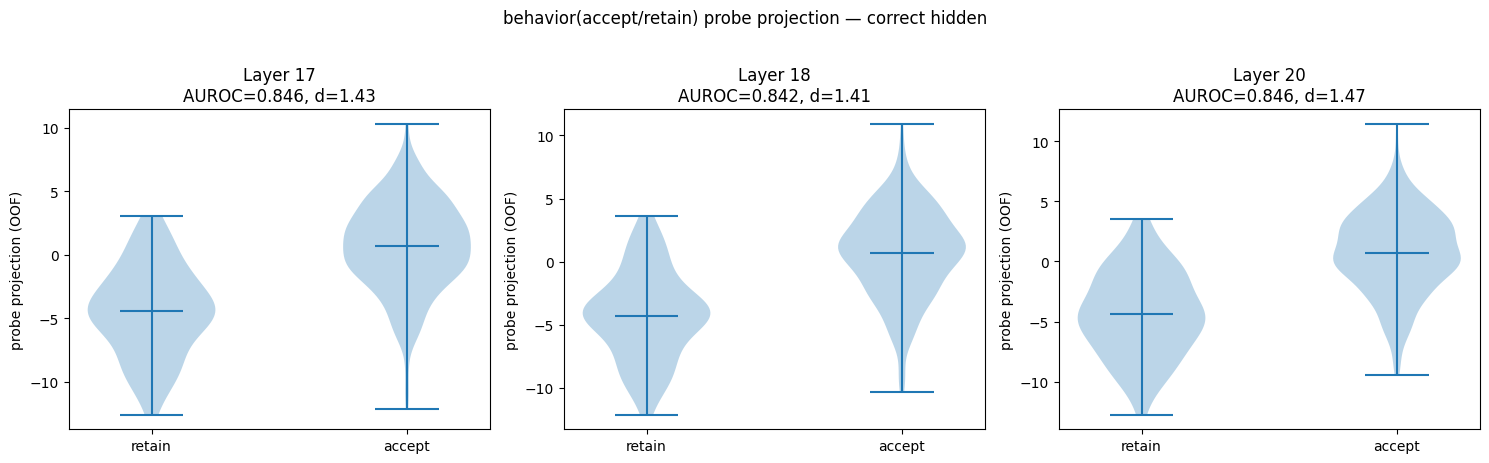

저장: behavior_projection_fixed.png


In [ ]:
import matplotlib.pyplot as plt

y = (meta["K"]=="K+").values.astype(int)
mb = ((meta["K"]=="K-") & meta["behavior"].isin(["accepted_context","retained_parametric"])).values
yb = (meta[mb]["behavior"]=="accepted_context").astype(int).values

def oof_proj(H, yy, groups):
    proj = np.zeros(len(yy))
    for tr,te in GroupKFold(5).split(H,yy,groups):
        sc=StandardScaler().fit(H[tr])
        clf=LogisticRegression(max_iter=1000,C=0.1).fit(sc.transform(H[tr]),yy[tr])
        proj[te]=sc.transform(H[te]) @ clf.coef_[0]
    return proj

# behavior probe 방향 투영 (L17/18/20)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, L in zip(axes, [17,18,20]):
    hL = layer(L)[mb]
    proj = oof_proj(hL, yb, meta[mb]["question"].values)
    auc = roc_auc_score(yb, proj)
    d = cohens_d(proj, yb)
    parts = ax.violinplot([proj[yb==0], proj[yb==1]], showmeans=True)
    ax.set_xticks([1,2]); ax.set_xticklabels(["retain","accept"])
    ax.set_title(f"Layer {L}\nAUROC={auc:.3f}, d={d:.2f}")
    ax.set_ylabel("probe projection (OOF)")
plt.suptitle("behavior(accept/retain) probe projection — correct hidden", y=1.02)
plt.tight_layout()
plt.savefig("behavior_projection_fixed.png", dpi=120, bbox_inches="tight")
plt.show()
print("저장: behavior_projection_fixed.png")

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import StandardScaler

mask_kn = (meta["K"]=="K-").values
h18 = layer(18)
H_kn = h18[mask_kn]
meta_kn = meta[mask_kn].reset_index(drop=True)

Xs = StandardScaler().fit_transform(H_kn)
Xp = PCA(n_components=30, random_state=42).fit_transform(Xs)

print("=== k별 silhouette + 라벨 정렬 ===")
for k in [2,3,4,5]:
    km = KMeans(k, random_state=42, n_init=10).fit(Xp)
    sil = silhouette_score(Xp, km.labels_)
    ari_d = adjusted_rand_score(meta_kn["dataset_id"], km.labels_)
    ari_b = adjusted_rand_score(meta_kn["behavior"].fillna("NaN"), km.labels_)
    nmi_d = normalized_mutual_info_score(meta_kn["dataset_id"], km.labels_)
    print(f"  k={k}: sil={sil:.3f} | dataset ARI={ari_d:.3f} NMI={nmi_d:.3f} | behavior ARI={ari_b:.3f}")

=== k별 silhouette + 라벨 정렬 ===
  k=2: sil=0.175 | dataset ARI=0.020 NMI=0.021 | behavior ARI=0.074
  k=3: sil=0.166 | dataset ARI=0.067 NMI=0.097 | behavior ARI=0.115
  k=4: sil=0.161 | dataset ARI=0.152 NMI=0.206 | behavior ARI=0.095
  k=5: sil=0.157 | dataset ARI=0.209 NMI=0.263 | behavior ARI=0.050


In [ ]:
k = 4
km = KMeans(k, random_state=42, n_init=10).fit(Xp)
meta_kn["cluster"] = km.labels_

# 1) 클러스터 × 라벨 교차표 (내부 구성)
print("=== 클러스터 크기 ===", np.bincount(km.labels_))
print("\n=== 클러스터 × dataset ===")
print(pd.crosstab(meta_kn["cluster"], meta_kn["dataset_id"]))
print("\n=== 클러스터 × behavior ===")
print(pd.crosstab(meta_kn["cluster"], meta_kn["behavior"]))
print("\n=== 클러스터 × fact_nature ===")
print(pd.crosstab(meta_kn["cluster"], meta_kn["fact_nature"]))

# 2) 각 클러스터 centroid 최근접 샘플 (케이스)
from scipy.spatial.distance import cdist
print("\n\n" + "="*70)
for c in range(k):
    idx = np.where(km.labels_==c)[0]
    centroid = Xp[idx].mean(0, keepdims=True)
    dists = cdist(Xp[idx], centroid).ravel()
    nearest = idx[np.argsort(dists)[:5]]  # centroid 최근접 5개
    sub = meta_kn.iloc[idx]
    print(f"\n### 클러스터 {c} (n={len(idx)}) ###")
    print(f"  dataset: {sub['dataset_id'].value_counts().to_dict()}")
    print(f"  behavior: {sub['behavior'].value_counts().head(3).to_dict()}")
    print(f"  fact_nature: {sub['fact_nature'].value_counts().to_dict()}")
    print(f"  instability 평균: {sub['instability'].mean():.3f} | prompt_len 평균: {sub['prompt_len'].mean():.0f}")
    print(f"  --- centroid 최근접 5개 케이스 ---")
    for i in nearest:
        r = meta_kn.iloc[i]
        print(f"    [{r['dataset_id']}/{r['behavior']}] Q: {r['question'][:50]}")
        print(f"       답변: {str(r['open_book_gen'])[:55]!r} | K={r['K']}")

=== 클러스터 크기 === [180 166 425 197]

=== 클러스터 × dataset ===
dataset_id  clasheval  confiqa_qa  dynamicqa  nqswap
cluster                                             
0                  11         114         29      26
1                   0          89         73       4
2                 179          15         99     132
3                  68          18         43      68

=== 클러스터 × behavior ===
behavior  abstain  accepted_context  both  other  retained_parametric
cluster                                                              
0              16                95    37     18                   14
1               0                84    12     52                   18
2               3               279    27     81                   35
3              72                66    11     32                   16

=== 클러스터 × fact_nature ===
fact_nature  disputable  static  temporal_mutable
cluster                                          
0                     2     174                 4
1

In [ ]:
# 케이스 스터디 결과를 파일로 저장
with open("case_study.txt", "w") as f:
    f.write("=== 클러스터 크기 ===\n")
    f.write(str(np.bincount(km.labels_)) + "\n\n")
    f.write("=== 클러스터 × dataset ===\n")
    f.write(pd.crosstab(meta_kn["cluster"], meta_kn["dataset_id"]).to_string() + "\n\n")
    f.write("=== 클러스터 × behavior ===\n")
    f.write(pd.crosstab(meta_kn["cluster"], meta_kn["behavior"]).to_string() + "\n\n")
    f.write("=== 클러스터 × fact_nature ===\n")
    f.write(pd.crosstab(meta_kn["cluster"], meta_kn["fact_nature"]).to_string() + "\n")

# 화면에도 출력
print(open("case_study.txt").read())

=== 클러스터 크기 ===
[180 166 425 197]

=== 클러스터 × dataset ===
dataset_id  clasheval  confiqa_qa  dynamicqa  nqswap
cluster                                             
0                  11         114         29      26
1                   0          89         73       4
2                 179          15         99     132
3                  68          18         43      68

=== 클러스터 × behavior ===
behavior  abstain  accepted_context  both  other  retained_parametric
cluster                                                              
0              16                95    37     18                   14
1               0                84    12     52                   18
2               3               279    27     81                   35
3              72                66    11     32                   16

=== 클러스터 × fact_nature ===
fact_nature  disputable  static  temporal_mutable
cluster                                          
0                     2     174                 4
1

In [ ]:
print("=== 클러스터가 무엇으로 갈렸나 (정량) ===")
# 길이 축
print("\n클러스터별 prompt_len:")
print(meta_kn.groupby("cluster")["prompt_len"].agg(["mean","median"]))

# abstain 비율
print("\n클러스터별 abstain 비율:")
print(meta_kn.groupby("cluster")["behavior"].apply(lambda x: (x=="abstain").mean()).round(3))

# 클러스터 vs 길이4분위 ARI (길이가 클러스터 설명하나)
meta_kn["len_q"] = pd.qcut(meta_kn["prompt_len"], 4, labels=False)
from sklearn.metrics import adjusted_rand_score
print("\n클러스터 vs 길이4분위 ARI:", round(adjusted_rand_score(meta_kn["len_q"], meta_kn["cluster"]), 3))
print("클러스터 vs abstain여부 ARI:", round(adjusted_rand_score((meta_kn["behavior"]=="abstain"), meta_kn["cluster"]), 3))
print("클러스터 vs dataset ARI:", round(adjusted_rand_score(meta_kn["dataset_id"], meta_kn["cluster"]), 3))
print("클러스터 vs fact_nature(type) ARI:", round(adjusted_rand_score(meta_kn["fact_nature"], meta_kn["cluster"]), 3))

=== 클러스터가 무엇으로 갈렸나 (정량) ===

클러스터별 prompt_len:
               mean  median
cluster                    
0        175.738889   161.0
1        143.915663   150.0
2        303.232941   259.0
3        297.553299   247.0

클러스터별 abstain 비율:
cluster
0    0.089
1    0.000
2    0.007
3    0.365
Name: behavior, dtype: float64

클러스터 vs 길이4분위 ARI: 0.068
클러스터 vs abstain여부 ARI: 0.073
클러스터 vs dataset ARI: 0.152
클러스터 vs fact_nature(type) ARI: 0.009


In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# === 4b: 클러스터가 무엇으로 갈렸나 (정량) ===
print("=== 클러스터별 길이/abstain ===")
print(meta_kn.groupby("cluster")["prompt_len"].agg(["mean","median"]))
print("\nabstain 비율:")
print(meta_kn.groupby("cluster")["behavior"].apply(lambda x:(x=="abstain").mean()).round(3))

meta_kn["len_q"] = pd.qcut(meta_kn["prompt_len"], 4, labels=False)
print("\n=== 클러스터 vs 각 축 ARI ===")
for name, col in [("길이4분위", meta_kn["len_q"]),
                  ("abstain여부", (meta_kn["behavior"]=="abstain")),
                  ("dataset", meta_kn["dataset_id"]),
                  ("behavior", meta_kn["behavior"]),
                  ("fact_nature(type)", meta_kn["fact_nature"])]:
    print(f"  {name:18s} ARI={adjusted_rand_score(col, meta_kn['cluster']):.3f}")

# === 5a: 셔플 널 (정렬이 우연인지) ===
print("\n=== 셔플 널 (라벨 섞은 뒤 ARI, 5회) ===")
for name, col in [("dataset", meta_kn["dataset_id"].values),
                  ("길이", meta_kn["len_q"].values)]:
    nulls = [adjusted_rand_score(np.random.permutation(col), meta_kn["cluster"]) for _ in range(5)]
    print(f"  {name}: 실제 {adjusted_rand_score(col, meta_kn['cluster']):.3f} vs 셔플 {np.mean(nulls):+.4f}")

# === 5b: DynamicQA 내부 클러스터링 (출처 상수 → 순수 type 테스트) ===
print("\n=== DynamicQA 단독 클러스터링 (static/temporal/disputable 갈리나) ===")
m_dyn = (meta["dataset_id"]=="dynamicqa") & (meta["K"]=="K-")
H_dyn = h18[m_dyn.values]
meta_dyn = meta[m_dyn].reset_index(drop=True)
print("fact_nature 분포:", meta_dyn["fact_nature"].value_counts().to_dict())

Xs_d = StandardScaler().fit_transform(H_dyn)
Xp_d = PCA(n_components=min(30, m_dyn.sum()-1), random_state=42).fit_transform(Xs_d)
for k in [2,3]:
    km_d = KMeans(k, random_state=42, n_init=10).fit(Xp_d)
    ari_fn = adjusted_rand_score(meta_dyn["fact_nature"], km_d.labels_)
    ari_b = adjusted_rand_score(meta_dyn["behavior"].fillna("NaN"), km_d.labels_)
    print(f"  k={k}: fact_nature ARI={ari_fn:.3f} | behavior ARI={ari_b:.3f}")

# === 5c: 길이 매칭 서브샘플 (길이 교란 제거 후 뭐 남나) ===
print("\n=== 길이 매칭 서브샘플 클러스터링 ===")
# 중앙 길이대만 (200~400 토큰) — 길이 편차 줄임
mid = (meta_kn["prompt_len"]>=150) & (meta_kn["prompt_len"]<=350)
Hm = Xp[mid.values]
mk = meta_kn[mid].reset_index(drop=True)
if len(Hm) > 50:
    for k in [3,4]:
        kmm = KMeans(k, random_state=42, n_init=10).fit(Hm)
        print(f"  k={k} (n={len(Hm)}): dataset ARI={adjusted_rand_score(mk['dataset_id'], kmm.labels_):.3f} "
              f"| behavior ARI={adjusted_rand_score(mk['behavior'].fillna('NaN'), kmm.labels_):.3f} "
              f"| type ARI={adjusted_rand_score(mk['fact_nature'], kmm.labels_):.3f}")

=== 클러스터별 길이/abstain ===
               mean  median
cluster                    
0        175.738889   161.0
1        143.915663   150.0
2        303.232941   259.0
3        297.553299   247.0

abstain 비율:
cluster
0    0.089
1    0.000
2    0.007
3    0.365
Name: behavior, dtype: float64

=== 클러스터 vs 각 축 ARI ===
  길이4분위              ARI=0.068
  abstain여부          ARI=0.073
  dataset            ARI=0.152
  behavior           ARI=0.095
  fact_nature(type)  ARI=0.009

=== 셔플 널 (라벨 섞은 뒤 ARI, 5회) ===
  dataset: 실제 0.152 vs 셔플 +0.0001
  길이: 실제 0.068 vs 셔플 +0.0003

=== DynamicQA 단독 클러스터링 (static/temporal/disputable 갈리나) ===
fact_nature 분포: {'static': 120, 'temporal_mutable': 94, 'disputable': 30}
  k=2: fact_nature ARI=0.000 | behavior ARI=0.191
  k=3: fact_nature ARI=0.035 | behavior ARI=0.171

=== 길이 매칭 서브샘플 클러스터링 ===
  k=3 (n=392): dataset ARI=0.042 | behavior ARI=0.078 | type ARI=-0.021
  k=4 (n=392): dataset ARI=0.189 | behavior ARI=0.044 | type ARI=-0.007


## 행동으로만 가능함. >> 유형별 MoE는 불가능해진 상황이다.

In [ ]:
# desired_action 분포 먼저
print("=== desired_action 분포 (K- 대상) ===")
print(meta[meta["K"]=="K-"]["desired_action"].value_counts())
print("\n=== dataset × desired_action ===")
print(pd.crosstab(meta[meta["K"]=="K-"]["dataset_id"], meta[meta["K"]=="K-"]["desired_action"]))

=== desired_action 분포 (K- 대상) ===
desired_action
accept                466
reject                258
needs_verification    244
Name: count, dtype: int64

=== dataset × desired_action ===
desired_action  accept  needs_verification  reject
dataset_id                                        
clasheval            0                   0     258
confiqa_qa         236                   0       0
dynamicqa            0                 244       0
nqswap             230                   0       0


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

# accept vs reject만 (needs_verification 제외), K-
m_ar = (meta["K"]=="K-") & meta["desired_action"].isin(["accept","reject"])
m_ar = m_ar.values
yd = (meta[m_ar]["desired_action"]=="accept").astype(int).values
dd = meta[m_ar]["dataset_id"].values
Hd = h18[m_ar]

# accept는 confiqa+nqswap, reject는 clasheval → LODO로 dataset 우회 테스트
print("=== desired_action LODO (accept 전이 가능한지) ===")
# confiqa로 accept 배우고 nqswap accept에 전이 (같은 accept, 다른 출처)
for hold in ["confiqa_qa", "nqswap"]:
    tr = dd != hold
    te = dd == hold
    if len(np.unique(yd[te]))<2:
        # 홀드아웃이 단일 클래스(accept만) → reject(clasheval)로 학습해서 이 accept 맞히나
        sc = StandardScaler().fit(Hd[tr])
        clf = LogisticRegression(max_iter=1000, C=0.1).fit(sc.transform(Hd[tr]), yd[tr])
        pred = clf.predict_proba(sc.transform(Hd[te]))[:,1]
        print(f"  holdout={hold} (전부 accept): 예측 accept 확률 평균 {pred.mean():.3f} (1에 가까울수록 맞힘)")

# 순수 비교: 같은 desired 내에서 dataset만 다를 때 hidden이 구분되나 (shortcut 크기)
print("\n=== accept 내부: confiqa vs nqswap 구분되나 (shortcut 크기) ===")
m_acc = (meta["K"]=="K-") & (meta["desired_action"]=="accept")
m_acc = m_acc.values
y_src = (meta[m_acc]["dataset_id"]=="confiqa_qa").astype(int).values
from sklearn.model_selection import cross_val_score
sc_auc = cross_val_score(LogisticRegression(max_iter=1000,C=0.1),
                         StandardScaler().fit_transform(h18[m_acc]), y_src,
                         cv=3, scoring="roc_auc").mean()
print(f"  confiqa vs nqswap (같은 accept): AUROC={sc_auc:.3f}")
print("  → 높으면 hidden이 출처를 강하게 구분 = desired probe는 이걸 탈 것")

=== desired_action LODO (accept 전이 가능한지) ===
  holdout=confiqa_qa (전부 accept): 예측 accept 확률 평균 0.759 (1에 가까울수록 맞힘)
  holdout=nqswap (전부 accept): 예측 accept 확률 평균 0.355 (1에 가까울수록 맞힘)

=== accept 내부: confiqa vs nqswap 구분되나 (shortcut 크기) ===
  confiqa vs nqswap (같은 accept): AUROC=1.000
  → 높으면 hidden이 출처를 강하게 구분 = desired probe는 이걸 탈 것


"모델 내부는 conflict를 유형이 아니라 행동 방향으로 표상하나(probe d 1.47), 그 행동 신호는 정답(desired)과 정렬되지 않고 출처·표면 특징과 교락되어 있다. 따라서 내부 신호 기반 라우팅(training-free MoE)은 현 설계로는 성립하지 않는다."

[라우터] 내부 신호 → accept/reject 판정 → expert 선택

[expert A] 수용: context 따라 답

[expert B] 저항: parametric 따라 답

In [ ]:
mask_kn = (meta["K"]=="K-").values
mk = meta[mask_kn].reset_index(drop=True)

# 타겟 1: behavior (accept vs retain, 이진)
mk["t_behavior"] = mk["behavior"].map({"accepted_context":1, "retained_parametric":0})

# 타겟 2: correctness (모델 답이 정답이었나)
# desired_action과 실제 behavior가 일치하면 correct
def is_correct(r):
    d = r["desired_action"]
    b = r["behavior"]
    if d=="accept":  return 1 if b=="accepted_context" else 0
    if d=="reject":  return 1 if b=="retained_parametric" else 0
    return np.nan  # needs_verification은 정답 애매 → 제외
mk["t_correct"] = mk.apply(is_correct, axis=1)

# 타겟 3: instability (연속 → 중앙값 기준 이진)
mk["t_unstable"] = (mk["instability"] > mk["instability"].median()).astype(int)

print("=== 타겟별 분포 ===")
for t in ["t_behavior","t_correct","t_unstable"]:
    print(f"\n{t}:")
    print("  값 분포:", mk[t].value_counts(dropna=False).to_dict())
    # dataset 교락 확인
    valid = mk[mk[t].notna()]
    ct = pd.crosstab(valid["dataset_id"], valid[t], normalize="index").round(2)
    print("  dataset별 비율:")
    print(ct.to_string().replace("\n","\n  "))

=== 타겟별 분포 ===

t_behavior:
  값 분포: {1.0: 524, nan: 361, 0.0: 83}
  dataset별 비율:
t_behavior   0.0   1.0
  dataset_id            
  clasheval   0.09  0.91
  confiqa_qa  0.12  0.88
  dynamicqa   0.13  0.87
  nqswap      0.21  0.79

t_correct:
  값 분포: {0.0: 468, 1.0: 256, nan: 244}
  dataset별 비율:
t_correct    0.0   1.0
  dataset_id            
  clasheval   0.93  0.07
  confiqa_qa  0.45  0.55
  nqswap      0.52  0.48

t_unstable:
  값 분포: {0: 715, 1: 253}
  dataset별 비율:
t_unstable     0     1
  dataset_id            
  clasheval   0.71  0.29
  confiqa_qa  0.78  0.22
  dynamicqa   0.71  0.29
  nqswap      0.76  0.24


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

h18 = layer(18)
# correct 타겟 있는 것만 (needs_verification 제외)
mc = mask_kn & meta["desired_action"].isin(["accept","reject"]).values
mc_meta = meta[mc].reset_index(drop=True)
yc = mc_meta.apply(lambda r: 1 if (
    (r["desired_action"]=="accept" and r["behavior"]=="accepted_context") or
    (r["desired_action"]=="reject" and r["behavior"]=="retained_parametric")
) else 0, axis=1).values
Hc = h18[mc]
gc_ = mc_meta["question"].values
dc = mc_meta["dataset_id"].values

def probe_auc(H, y, groups):
    gkf=GroupKFold(5); a=[]
    for tr,te in gkf.split(H,y,groups):
        sc=StandardScaler().fit(H[tr])
        clf=LogisticRegression(max_iter=1000,C=0.1).fit(sc.transform(H[tr]),y[tr])
        if len(np.unique(y[te]))>1:
            a.append(roc_auc_score(y[te],clf.predict_proba(sc.transform(H[te]))[:,1]))
    return np.mean(a) if a else np.nan

print("=== correctness 라우터 probe ===")
print(f"전체 correct율: {yc.mean():.2f} (n={len(yc)})")
print(f"\npooled AUROC: {probe_auc(Hc, yc, gc_):.3f}")
print("  (단 pooled는 dataset이 correct와 상관 — clasheval 93% incorrect)")

print("\n=== within-dataset (dataset shortcut 배제) ===")
for did in ["confiqa_qa","nqswap"]:  # 균형된 것만
    m = dc==did
    if len(np.unique(yc[m]))<2: continue
    auc = probe_auc(Hc[m], yc[m], gc_[m])
    print(f"  {did} (n={m.sum()}, correct율={yc[m].mean():.2f}): AUROC={auc:.3f}")

=== correctness 라우터 probe ===
전체 correct율: 0.35 (n=724)

pooled AUROC: 0.807
  (단 pooled는 dataset이 correct와 상관 — clasheval 93% incorrect)

=== within-dataset (dataset shortcut 배제) ===
  confiqa_qa (n=236, correct율=0.55): AUROC=0.826
  nqswap (n=230, correct율=0.48): AUROC=0.690


[라우터] L18 hidden → correctness probe → "틀릴 것 같으면 개입 신호"
[개입/expert] 틀릴 것 같을 때 → 행동을 뒤집는 조작
   - accept해야 하는데 retain하려 하면 → context 쪽으로
   - reject해야 하는데 accept하려 하면 → parametric 쪽으로